# Credit Card Fraud Detection — Modeling & Hybrid Ensemble

This notebook continues the EDA notebook and builds the complete machine-learning stage.

### Objectives
- Leakage-safe train/validation/test splitting
- Class-imbalance handling
- Multiple ML model families
- Model comparison using fraud-appropriate metrics
- Hyperparameter tuning
- Hybrid stacking ensemble
- Threshold optimization
- Final untouched test evaluation
- Feature importance and optional SHAP
- Saving the final model

> Accuracy is not the main metric because fraud is extremely rare. Focus on Precision, Recall, F1, ROC-AUC and PR-AUC.


**Important:** Run this notebook from top to bottom. The original test split is kept untouched; do not rerun a split using the full dataset later in the notebook.


In [1]:
# If a package is missing in Kaggle, uncomment:
# !pip install -q xgboost lightgbm catboost imbalanced-learn shap

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    HistGradientBoostingClassifier, StackingClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import RandomUnderSampler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42

## 1. Load the Kaggle dataset

In [2]:
# Load Credit Card Fraud Detection dataset.
# In Kaggle, first use "Add Input" to attach the dataset:
# mlg-ulb/creditcardfraud. Non-interactive notebook runs cannot attach new datasets.

import os
import glob
import pandas as pd

possible_paths = [
    "/kaggle/input/creditcardfraud/creditcard.csv",
    "/kaggle/input/credit-card-fraud-detection/creditcard.csv",
    "./creditcard.csv",
    "/content/creditcard.csv",
]

# Search all Kaggle input folders as dataset folder names can vary.
possible_paths.extend(glob.glob("/kaggle/input/**/creditcard.csv", recursive=True))

csv_path = next((p for p in possible_paths if os.path.isfile(p)), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find creditcard.csv. In Kaggle, click 'Add Input' "
        "on the right side, search for 'Credit Card Fraud Detection' "
        "(dataset owner: mlg-ulb), and add it to this notebook. "
        "Then rerun this cell. Alternatively, upload creditcard.csv "
        "to the notebook working directory."
    )

df = pd.read_csv(csv_path)

print("Dataset loaded from:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())

print("\nClass distribution:")
display(df["Class"].value_counts())

Dataset loaded from: /kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Class distribution:


Class
0    284315
1       492
Name: count, dtype: int64

## 2. Prepare features and target

In [3]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].copy()

print("Features:", X.shape[1])
print("Samples:", X.shape[0])
print("Fraud cases:", int(y.sum()))
print("Fraud rate: {:.4f}%".format(y.mean() * 100))


Features: 30
Samples: 284807
Fraud cases: 492
Fraud rate: 0.1727%


## 3. Train / validation / test split

The test set stays completely untouched. Resampling is applied only to training data.


In [4]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, stratify=y_train_full, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Fraud:", int(y_train.sum()))
print("Validation:", X_val.shape, "Fraud:", int(y_val.sum()))
print("Test:", X_test.shape, "Fraud:", int(y_test.sum()))


Train: (182276, 30) Fraud: 315
Validation: (45569, 30) Fraud: 79
Test: (56962, 30) Fraud: 98


## 4. Scaling

The scaler is fitted on the training set only. The scaled copies are used for distance-based resampling (SMOTE / Tomek links) and for the SMOTE experiments. Linear, KNN, SVM and neural-network models use their own scaler inside a `Pipeline`.

In [5]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

display(X_train_scaled.head())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
1458,-1.974950,-0.226090,0.656801,0.929813,0.069981,0.100679,-0.532912,0.544715,0.011182,-0.461933,-0.526678,0.393147,0.424772,0.628857,-0.517592,1.158752,-0.036219,0.440112,-0.907136,-0.709507,0.170863,-0.279533,-0.651848,0.106757,0.604158,-0.487761,0.164303,0.661525,0.310497,-0.329104
119883,-0.406035,0.626376,0.102080,0.215806,0.349803,-0.089034,-0.235426,-0.008935,-0.040809,0.053212,-0.105861,-0.301577,0.358078,0.404066,0.249917,1.428221,0.131285,-0.326898,-1.044278,-0.424111,-0.123211,-0.341880,-0.965340,0.187064,-0.477466,0.367264,0.301835,-0.036534,0.041917,-0.317540
177219,0.593788,0.872427,-0.426019,-0.634421,0.336776,-0.190063,0.182330,-0.483911,0.046412,1.060488,-0.592216,-0.969211,0.451725,1.499603,-1.961621,0.965955,1.471366,-0.016511,0.949156,-0.383925,0.419544,0.040111,-0.117321,0.127280,-0.026693,-0.908436,0.752677,-0.040967,0.070618,0.340220
191980,0.728484,1.070889,0.056061,-1.420631,0.676337,0.787622,-0.046643,0.352938,-0.103718,0.176020,0.423680,-0.667359,0.008534,-1.145630,0.889001,-1.099171,-0.106645,-0.966745,0.488717,0.731924,-0.432577,-0.010303,0.207554,-0.272555,-2.426441,1.114538,-0.867158,-0.064844,-0.276427,-0.354147
252575,1.284285,-0.291229,-0.582812,1.322540,-1.120722,-0.135700,-0.635775,-0.572498,-0.004816,1.775682,-1.092759,-0.785258,0.027179,-0.319730,-0.475520,2.165031,-0.677317,-0.210963,1.044573,1.622150,0.422693,0.497477,1.700612,-0.000739,0.051481,-1.393837,-0.173956,0.171476,-0.024175,-0.271892


## 5. Evaluation functions

In [6]:
def get_probabilities(model, X_data):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_data)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X_data)
    raise ValueError("Model must support predict_proba() or decision_function().")

def predictions_at_threshold(probabilities, threshold=0.50):
    return (np.asarray(probabilities) >= threshold).astype(int)

def evaluate_predictions(y_true, y_pred, y_prob, model_name, threshold=0.50):
    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob)
    }

def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 6. Logistic Regression baseline

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.5,0.975707,0.059932,0.886076,0.112269,0.973616,0.679035


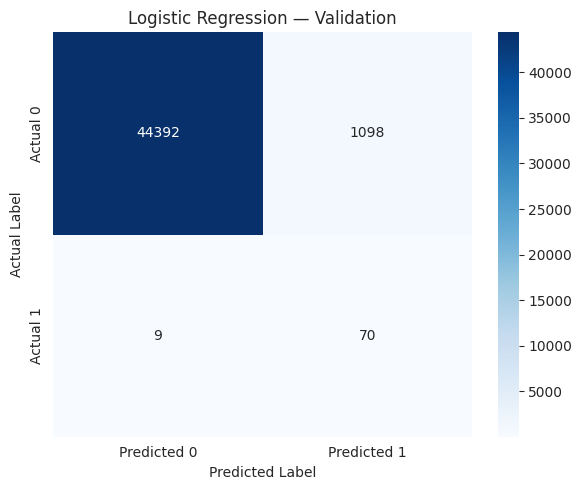

In [7]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
log_prob = get_probabilities(logistic_model, X_val)
log_pred = predictions_at_threshold(log_prob)

log_result = evaluate_predictions(
    y_val, log_pred, log_prob, "Logistic Regression"
)
display(pd.DataFrame([log_result]))
show_confusion(y_val, log_pred, "Logistic Regression — Validation")


## 7. Decision Tree and Random Forest

In [8]:
tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=12,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

tree_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

tree_prob = get_probabilities(tree_model, X_val)
rf_prob = get_probabilities(rf_model, X_val)

tree_result = evaluate_predictions(
    y_val, predictions_at_threshold(tree_prob), tree_prob, "Decision Tree"
)
rf_result = evaluate_predictions(
    y_val, predictions_at_threshold(rf_prob), rf_prob, "Random Forest"
)

display(pd.DataFrame([tree_result, rf_result]))


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Decision Tree,0.5,0.997367,0.371069,0.746835,0.495798,0.873049,0.643917
1,Random Forest,0.5,0.999407,0.906250,0.734177,0.811189,0.950195,0.812957


## 8. Extra Trees and HistGradientBoosting

In [9]:
extra_model = ExtraTreesClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

hist_model = HistGradientBoostingClassifier(
    max_iter=250,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=RANDOM_STATE
)

extra_model.fit(X_train, y_train)
hist_model.fit(X_train, y_train)

extra_prob = get_probabilities(extra_model, X_val)
hist_prob = get_probabilities(hist_model, X_val)

extra_result = evaluate_predictions(
    y_val, predictions_at_threshold(extra_prob), extra_prob, "Extra Trees"
)
hist_result = evaluate_predictions(
    y_val, predictions_at_threshold(hist_prob), hist_prob, "HistGradientBoosting"
)

display(pd.DataFrame([extra_result, hist_result]))


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Extra Trees,0.5,0.999429,0.907692,0.746835,0.819444,0.960746,0.823350
1,HistGradientBoosting,0.5,0.999407,0.871429,0.772152,0.818792,0.978093,0.799599


## 9. XGBoost

In [10]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count

print("scale_pos_weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=2,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

xgb_model.fit(X_train, y_train)
xgb_prob = get_probabilities(xgb_model, X_val)

xgb_result = evaluate_predictions(
    y_val, predictions_at_threshold(xgb_prob), xgb_prob, "XGBoost"
)
display(pd.DataFrame([xgb_result]))


scale_pos_weight: 577.6539682539683


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,XGBoost,0.5,0.999473,0.898551,0.78481,0.837838,0.97619,0.835075


## 10. LightGBM

In [11]:
lgb_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=0.85,
    class_weight="balanced",
    objective="binary",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)
lgb_prob = get_probabilities(lgb_model, X_val)

lgb_result = evaluate_predictions(
    y_val, predictions_at_threshold(lgb_prob), lgb_prob, "LightGBM"
)
display(pd.DataFrame([lgb_result]))


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LightGBM,0.5,0.999539,0.926471,0.797468,0.857143,0.974613,0.840051


## 11. CatBoost

In [12]:
cat_model = CatBoostClassifier(
    iterations=500,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    verbose=False,
    random_seed=RANDOM_STATE
)

cat_model.fit(X_train, y_train)
cat_prob = get_probabilities(cat_model, X_val)

cat_result = evaluate_predictions(
    y_val, predictions_at_threshold(cat_prob), cat_prob, "CatBoost"
)
display(pd.DataFrame([cat_result]))


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,CatBoost,0.5,0.999342,0.826667,0.78481,0.805195,0.969633,0.814516


## 12. KNN, SVM and Neural Network

In [13]:
# SVC with probability=True is very slow on ~180k rows (training cost grows
# roughly quadratically). Train the SVM on all fraud rows plus a random
# sample of 20,000 legitimate rows. Validation/test sets are NOT resampled.
rng = np.random.RandomState(RANDOM_STATE)
neg_idx = y_train[y_train == 0].index.to_numpy()
pos_idx = y_train[y_train == 1].index.to_numpy()
svm_idx = np.concatenate([rng.choice(neg_idx, size=20000, replace=False), pos_idx])
X_train_svm, y_train_svm = X_train.loc[svm_idx], y_train.loc[svm_idx]

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=15, weights="distance", n_jobs=-1
    ))
])

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        C=2.0,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=0.0005,
        batch_size=512,
        learning_rate_init=0.001,
        max_iter=40,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE
    ))
])

knn_model.fit(X_train, y_train)
knn_prob = get_probabilities(knn_model, X_val)

svm_model.fit(X_train_svm, y_train_svm)
svm_prob = get_probabilities(svm_model, X_val)

mlp_model.fit(X_train, y_train)
mlp_prob = get_probabilities(mlp_model, X_val)

knn_result = evaluate_predictions(
    y_val, predictions_at_threshold(knn_prob), knn_prob, "KNN"
)
svm_result = evaluate_predictions(
    y_val, predictions_at_threshold(svm_prob), svm_prob, "SVM"
)
mlp_result = evaluate_predictions(
    y_val, predictions_at_threshold(mlp_prob), mlp_prob, "Neural Network"
)

display(pd.DataFrame([knn_result, svm_result, mlp_result]))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,KNN,0.5,0.999386,0.880597,0.746835,0.808219,0.917461,0.794868
1,SVM,0.5,0.996972,0.321212,0.670886,0.434426,0.968550,0.423753
2,Neural Network,0.5,0.999320,0.863636,0.721519,0.786207,0.951356,0.744464


## 13. Compare all initial models

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
6,LightGBM,0.5,0.999539,0.926471,0.797468,0.857143,0.974613,0.840051
5,XGBoost,0.5,0.999473,0.898551,0.784810,0.837838,0.976190,0.835075
3,Extra Trees,0.5,0.999429,0.907692,0.746835,0.819444,0.960746,0.823350
7,CatBoost,0.5,0.999342,0.826667,0.784810,0.805195,0.969633,0.814516
2,Random Forest,0.5,0.999407,0.906250,0.734177,0.811189,0.950195,0.812957
4,HistGradientBoosting,0.5,0.999407,0.871429,0.772152,0.818792,0.978093,0.799599
8,KNN,0.5,0.999386,0.880597,0.746835,0.808219,0.917461,0.794868
10,Neural Network,0.5,0.999320,0.863636,0.721519,0.786207,0.951356,0.744464
0,Logistic Regression,0.5,0.975707,0.059932,0.886076,0.112269,0.973616,0.679035
1,Decision Tree,0.5,0.997367,0.371069,0.746835,0.495798,0.873049,0.643917


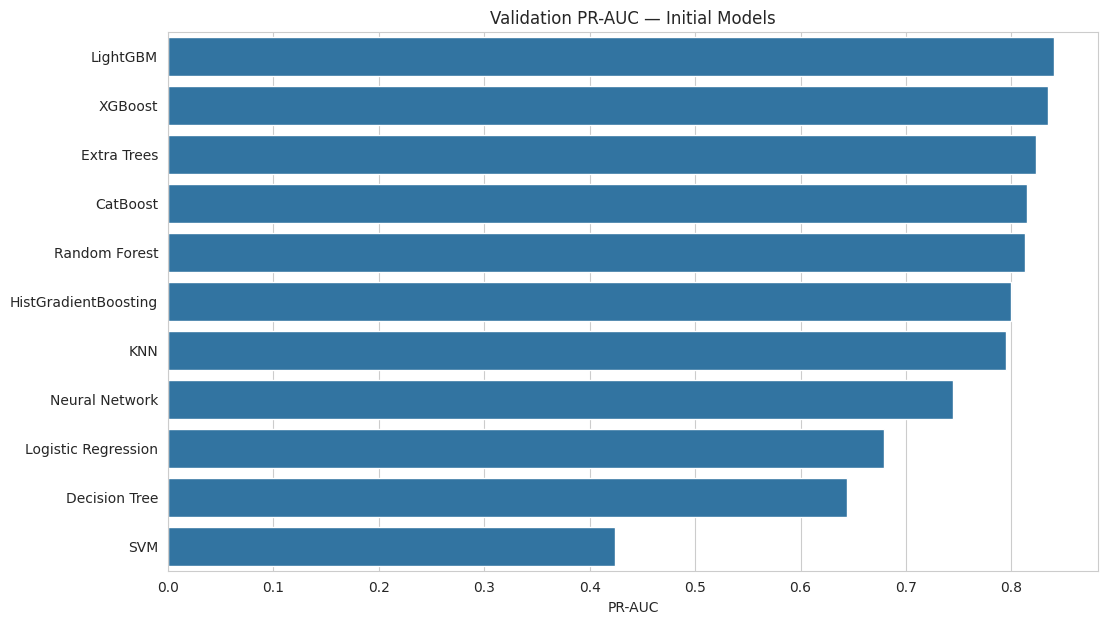

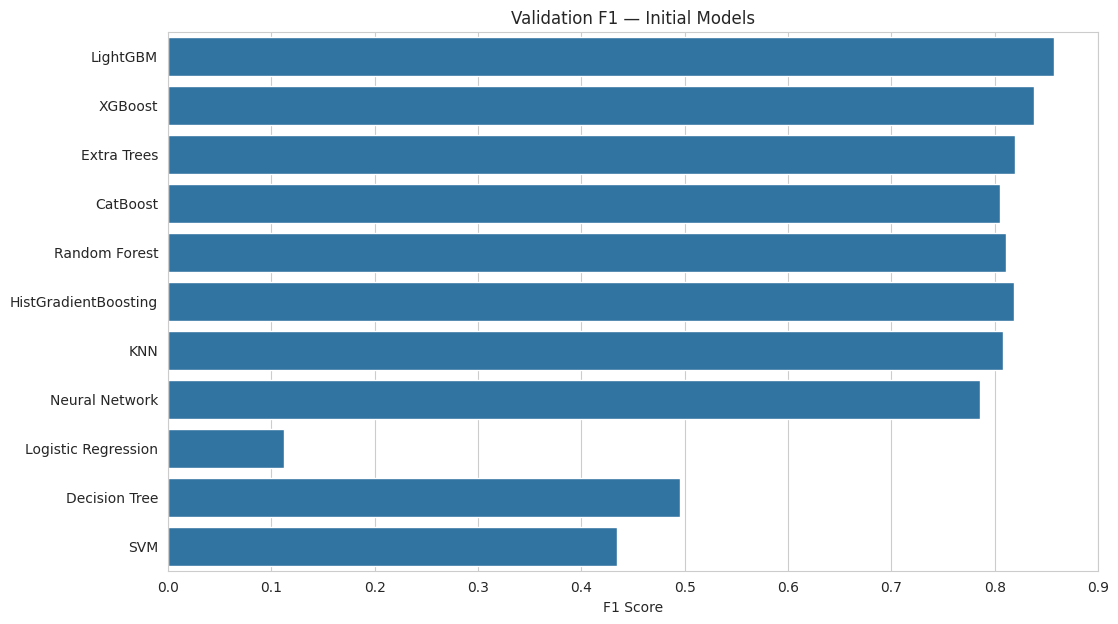

In [14]:
initial_results = pd.DataFrame([
    log_result, tree_result, rf_result, extra_result,
    hist_result, xgb_result, lgb_result, cat_result,
    knn_result, svm_result, mlp_result
]).sort_values("PR_AUC", ascending=False)

display(initial_results)

plt.figure(figsize=(12, 7))
sns.barplot(data=initial_results, x="PR_AUC", y="Model")
plt.title("Validation PR-AUC — Initial Models")
plt.xlabel("PR-AUC")
plt.ylabel("")
plt.show()

plt.figure(figsize=(12, 7))
sns.barplot(data=initial_results, x="F1", y="Model")
plt.title("Validation F1 — Initial Models")
plt.xlabel("F1 Score")
plt.ylabel("")
plt.show()


## 14. Random Undersampling

In [15]:
rus = RandomUnderSampler(
    sampling_strategy=0.10,
    random_state=RANDOM_STATE
)

X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

print("Before:", X_train.shape)
print("After:", X_train_rus.shape)
print(pd.Series(y_train_rus).value_counts())

rf_rus = RandomForestClassifier(
    n_estimators=300,
    max_depth=18,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_rus.fit(X_train_rus, y_train_rus)
rf_rus_prob = get_probabilities(rf_rus, X_val)

rf_rus_result = evaluate_predictions(
    y_val,
    predictions_at_threshold(rf_rus_prob),
    rf_rus_prob,
    "Random Forest + Undersampling"
)

display(pd.DataFrame([rf_rus_result]))


Before: (182276, 30)
After: (3465, 30)
Class
0    3150
1     315
Name: count, dtype: int64


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest + Undersampling,0.5,0.998135,0.477941,0.822785,0.604651,0.968824,0.700034


## 15. SMOTE

In [16]:
smote = SMOTE(
    sampling_strategy=0.10,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE:", X_train_smote.shape)
print(pd.Series(y_train_smote).value_counts())

lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr_smote.fit(X_train_smote, y_train_smote)
lr_smote_prob = get_probabilities(lr_smote, X_val_scaled)

lr_smote_result = evaluate_predictions(
    y_val,
    predictions_at_threshold(lr_smote_prob),
    lr_smote_prob,
    "Logistic Regression + SMOTE"
)

display(pd.DataFrame([lr_smote_result]))

After SMOTE: (200157, 30)
Class
0    181961
1     18196
Name: count, dtype: int64


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression + SMOTE,0.5,0.996555,0.3125,0.822785,0.452962,0.967657,0.695976


## 16. SMOTETomek

In [17]:
smotetomek = SMOTETomek(
    sampling_strategy=0.10,
    random_state=RANDOM_STATE
)

X_train_st, y_train_st = smotetomek.fit_resample(X_train_scaled, y_train)

print("After SMOTETomek:", X_train_st.shape)
print(pd.Series(y_train_st).value_counts())

extra_st = ExtraTreesClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

extra_st.fit(X_train_st, y_train_st)
extra_st_prob = get_probabilities(extra_st, X_val_scaled)

extra_st_result = evaluate_predictions(
    y_val,
    predictions_at_threshold(extra_st_prob),
    extra_st_prob,
    "Extra Trees + SMOTETomek"
)

display(pd.DataFrame([extra_st_result]))

After SMOTETomek: (200157, 30)
Class
0    181961
1     18196
Name: count, dtype: int64


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Extra Trees + SMOTETomek,0.5,0.999407,0.861111,0.78481,0.821192,0.964023,0.825054


## 17. Resampling comparison

In [18]:
resampling_results = pd.DataFrame([
    rf_rus_result, lr_smote_result, extra_st_result
]).sort_values("PR_AUC", ascending=False)

display(resampling_results)


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Extra Trees + SMOTETomek,0.5,0.999407,0.861111,0.784810,0.821192,0.964023,0.825054
0,Random Forest + Undersampling,0.5,0.998135,0.477941,0.822785,0.604651,0.968824,0.700034
1,Logistic Regression + SMOTE,0.5,0.996555,0.312500,0.822785,0.452962,0.967657,0.695976


## 18. XGBoost hyperparameter tuning

In [19]:
xgb_candidates = [
    {"n_estimators": 350, "max_depth": 4, "learning_rate": 0.05,
     "min_child_weight": 2, "subsample": 0.90, "colsample_bytree": 0.90},
    {"n_estimators": 500, "max_depth": 5, "learning_rate": 0.05,
     "min_child_weight": 2, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 500, "max_depth": 7, "learning_rate": 0.03,
     "min_child_weight": 3, "subsample": 0.85, "colsample_bytree": 0.85}
]

xgb_tuning_rows = []
tuned_xgb_models = []

for i, params in enumerate(xgb_candidates, 1):
    model = XGBClassifier(
        **params,
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_val)[:, 1]
    xgb_tuning_rows.append(
        evaluate_predictions(
            y_val, predictions_at_threshold(prob), prob, f"XGBoost Tune {i}"
        )
    )
    tuned_xgb_models.append(model)

xgb_tuning_results = pd.DataFrame(xgb_tuning_rows).sort_values(
    "PR_AUC", ascending=False
)
display(xgb_tuning_results)

# After sort_values the index labels still point to positions in tuned_xgb_models.
best_xgb_index = xgb_tuning_results.index[0]
best_xgb = tuned_xgb_models[best_xgb_index]
best_xgb_result = xgb_tuning_results.iloc[0].to_dict()
print("Best XGBoost configuration:", best_xgb_result["Model"])

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,XGBoost Tune 2,0.5,0.999429,0.884058,0.772152,0.824324,0.976885,0.841049
2,XGBoost Tune 3,0.5,0.999451,0.885714,0.784810,0.832215,0.974154,0.833245
0,XGBoost Tune 1,0.5,0.999254,0.777778,0.797468,0.787500,0.971578,0.817023


Best XGBoost configuration: XGBoost Tune 2


## 19. Random Forest hyperparameter tuning

In [20]:
rf_candidates = [
    {"n_estimators": 300, "max_depth": 12, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 400, "max_depth": 18, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 400, "max_depth": None, "min_samples_leaf": 3, "max_features": 0.3},
]

rf_tuning_rows = []
tuned_rf_models = []

for i, params in enumerate(rf_candidates, 1):
    model = RandomForestClassifier(
        **params,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)
    prob = get_probabilities(model, X_val)
    rf_tuning_rows.append(
        evaluate_predictions(
            y_val, predictions_at_threshold(prob), prob, f"Random Forest Tune {i}"
        )
    )
    tuned_rf_models.append(model)

rf_tuning_results = pd.DataFrame(rf_tuning_rows).sort_values("PR_AUC", ascending=False)
display(rf_tuning_results)

best_rf_index = rf_tuning_results.index[0]
best_rf = tuned_rf_models[best_rf_index]
best_rf_result = rf_tuning_results.iloc[0].to_dict()
print("Best Random Forest configuration:", best_rf_result["Model"])

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Random Forest Tune 3,0.5,0.999451,0.909091,0.759494,0.827586,0.943990,0.817048
1,Random Forest Tune 2,0.5,0.999386,0.904762,0.721519,0.802817,0.949949,0.815316
0,Random Forest Tune 1,0.5,0.999364,0.878788,0.734177,0.800000,0.968925,0.794245


Best Random Forest configuration: Random Forest Tune 3


## 20. Hybrid Stacking Ensemble

The hybrid model combines:
- Logistic Regression
- Random Forest
- XGBoost
- LightGBM
- CatBoost

A Logistic Regression meta-model learns how to combine their probability predictions.


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Hybrid Stacking Ensemble,0.5,0.9995,0.9219,0.7468,0.8252,0.9739,0.8222


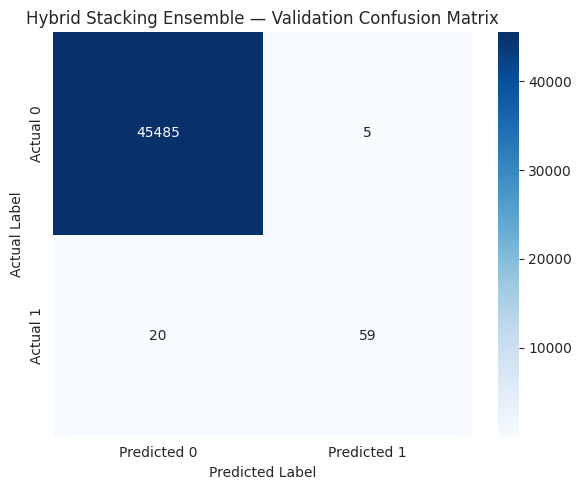

In [21]:
THRESHOLD = 0.50

def build_stacking_model():
    """Return a NEW, unfitted hybrid stacking ensemble (used for validation and final refit)."""
    base_estimators = [
        ("lr", Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
            ))
        ])),
        ("rf", RandomForestClassifier(
            n_estimators=200, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=1
        )),
        ("xgb", XGBClassifier(
            n_estimators=200, max_depth=6, learning_rate=0.1,
            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1
        )),
        ("lgb", LGBMClassifier(
            n_estimators=200, learning_rate=0.1, objective="binary",
            random_state=RANDOM_STATE, verbosity=-1, n_jobs=1
        )),
        ("cat", CatBoostClassifier(
            iterations=200, learning_rate=0.1, depth=6,
            random_seed=RANDOM_STATE, verbose=0,
            allow_writing_files=False, thread_count=1
        )),
    ]
    # The meta-model has NO class_weight, so its probabilities stay calibrated
    # and the threshold search below is meaningful.
    return StackingClassifier(
        estimators=base_estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        stack_method="predict_proba",
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1
    )

stacking_model = build_stacking_model()
stacking_model.fit(X_train, y_train)

stack_prob = stacking_model.predict_proba(X_val)[:, 1]
stack_pred = predictions_at_threshold(stack_prob, THRESHOLD)

stack_result = evaluate_predictions(
    y_val, stack_pred, stack_prob, "Hybrid Stacking Ensemble", threshold=THRESHOLD
)
display(pd.DataFrame([stack_result]).round(4))
show_confusion(y_val, stack_pred, "Hybrid Stacking Ensemble — Validation Confusion Matrix")

## 21. Compare strong models

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,XGBoost Tune 2,0.5,0.999429,0.884058,0.772152,0.824324,0.976885,0.841049
1,LightGBM,0.5,0.999539,0.926471,0.797468,0.857143,0.974613,0.840051
2,XGBoost,0.5,0.999473,0.898551,0.784810,0.837838,0.976190,0.835075
3,Extra Trees + SMOTETomek,0.5,0.999407,0.861111,0.784810,0.821192,0.964023,0.825054
4,Extra Trees,0.5,0.999429,0.907692,0.746835,0.819444,0.960746,0.823350
5,Hybrid Stacking Ensemble,0.5,0.999451,0.921875,0.746835,0.825175,0.973885,0.822173
6,Random Forest Tune 3,0.5,0.999451,0.909091,0.759494,0.827586,0.943990,0.817048
7,CatBoost,0.5,0.999342,0.826667,0.784810,0.805195,0.969633,0.814516
8,Random Forest,0.5,0.999407,0.906250,0.734177,0.811189,0.950195,0.812957
9,Random Forest + Undersampling,0.5,0.998135,0.477941,0.822785,0.604651,0.968824,0.700034


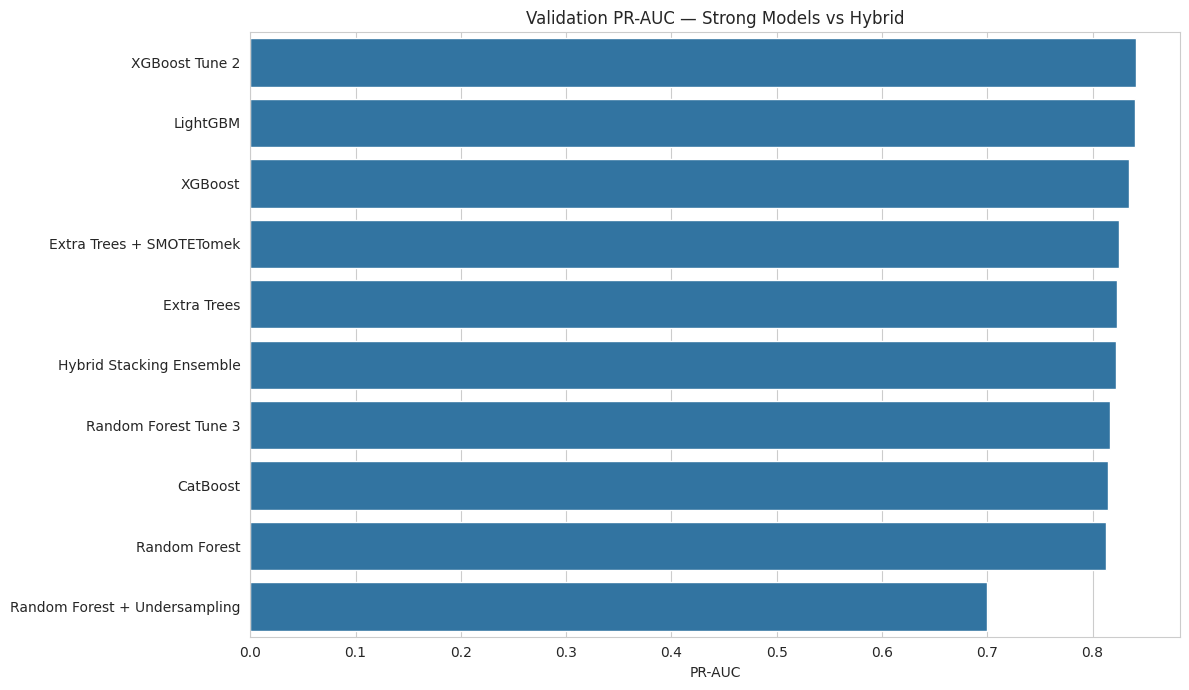

In [22]:
strong_results = pd.DataFrame([
    xgb_result, best_xgb_result,
    lgb_result, cat_result,
    rf_result, best_rf_result,
    extra_result, extra_st_result, rf_rus_result,
    stack_result
]).sort_values("PR_AUC", ascending=False).reset_index(drop=True)

display(strong_results)

plt.figure(figsize=(12, 7))
sns.barplot(data=strong_results, x="PR_AUC", y="Model")
plt.title("Validation PR-AUC — Strong Models vs Hybrid")
plt.xlabel("PR-AUC")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 22. Decision threshold optimization

The default probability threshold of 0.50 is not necessarily optimal for fraud detection. We choose the threshold using the validation set, then freeze it before testing.


Best validation threshold: 0.0509


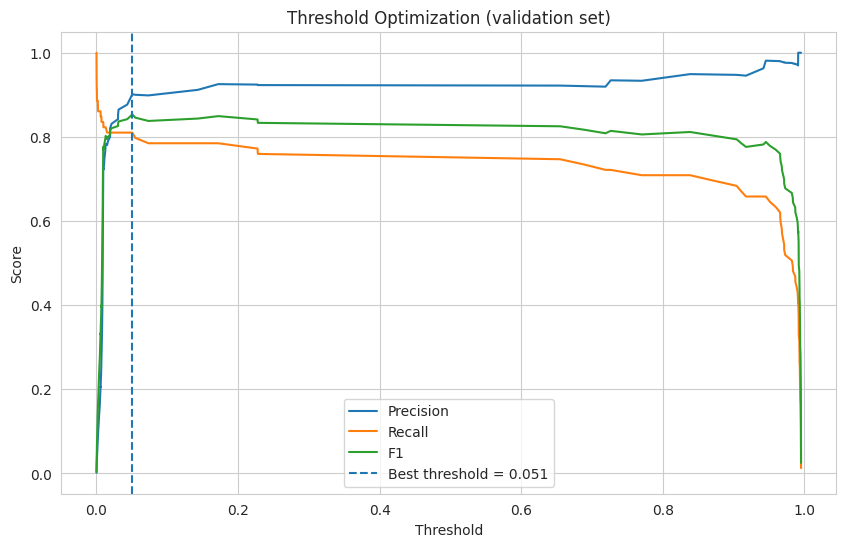

In [23]:
def find_best_threshold(y_true, probabilities):
    """Pick the threshold with the highest F1 using every score from the PR curve."""
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    precision, recall = precision[:-1], recall[:-1]          # align with thresholds
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom,
                   out=np.zeros_like(denom), where=denom > 0)
    table = pd.DataFrame({
        "threshold": thresholds, "precision": precision,
        "recall": recall, "f1": f1
    })
    best = table.loc[table["f1"].idxmax()]
    return float(best["threshold"]), table

best_threshold, threshold_table = find_best_threshold(y_val, stack_prob)
print("Best validation threshold:", round(best_threshold, 4))

plt.figure(figsize=(10, 6))
plt.plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
plt.plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
plt.plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Best threshold = {best_threshold:.3f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization (validation set)")
plt.legend()
plt.show()

## 23. Optimized hybrid validation result

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Hybrid Stacking — Optimized Threshold,0.050851,0.999517,0.901408,0.810127,0.853333,0.973885,0.822173


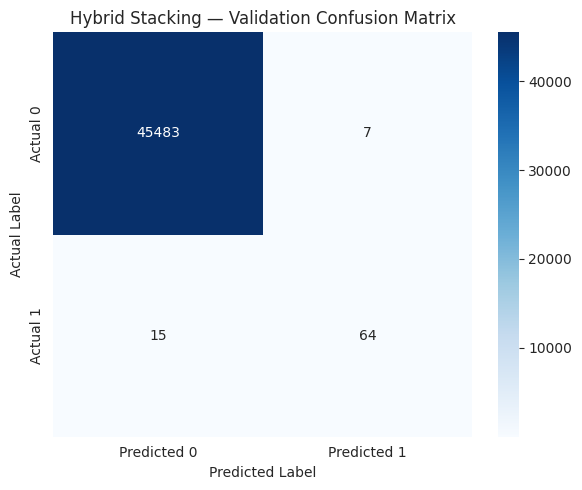

In [24]:
stack_val_pred_opt = predictions_at_threshold(stack_prob, best_threshold)

stack_opt_result = evaluate_predictions(
    y_val, stack_val_pred_opt, stack_prob,
    "Hybrid Stacking — Optimized Threshold",
    threshold=best_threshold
)

display(pd.DataFrame([stack_opt_result]))
show_confusion(
    y_val, stack_val_pred_opt,
    "Hybrid Stacking — Validation Confusion Matrix"
)


## 24. Refit final hybrid model using train + validation

After selecting the model and threshold, combine train and validation. The test set remains untouched.


In [25]:
# Final refit: combine training + validation data.
# X_test / y_test stay untouched until the final evaluation.
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

final_stacking_model = build_stacking_model()      # identical configuration
final_stacking_model.fit(X_train_final, y_train_final)

# Standalone XGBoost for feature importance and SHAP.
final_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=(y_train_final == 0).sum() / max((y_train_final == 1).sum(), 1),
    random_state=RANDOM_STATE,
    n_jobs=-1
)
final_xgb.fit(X_train_final, y_train_final)

print("Final hybrid stacking model trained.")
print("Final XGBoost model trained for feature importance.")
print("Train + validation shape:", X_train_final.shape)
print("Held-out test shape:", X_test.shape)

Final hybrid stacking model trained.
Final XGBoost model trained for feature importance.
Train + validation shape: (227845, 30)
Held-out test shape: (56962, 30)


## 25. Final test confusion matrix and classification report

Selected threshold (chosen on validation): 0.0509

Classification report:
              precision    recall  f1-score   support

           0     0.9998    0.9997    0.9997     56864
           1     0.8400    0.8571    0.8485        98

    accuracy                         0.9995     56962
   macro avg     0.9199    0.9284    0.9241     56962
weighted avg     0.9995    0.9995    0.9995     56962



,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Final Hybrid Stacking — Test,0.0509,0.9995,0.84,0.8571,0.8485,0.9722,0.8652


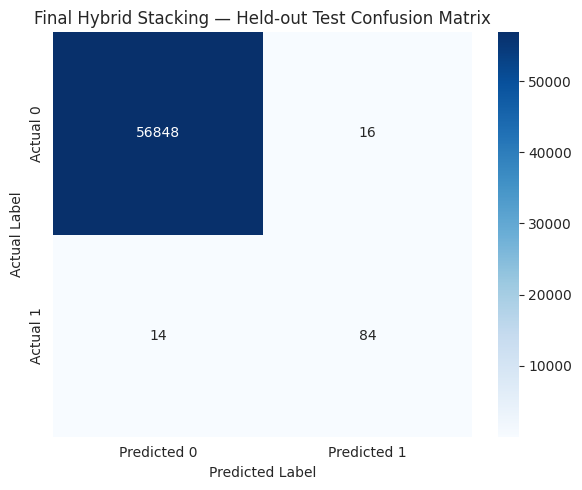

In [26]:
# Final held-out test evaluation (threshold was chosen on validation only).
test_prob = final_stacking_model.predict_proba(X_test)[:, 1]
test_pred = predictions_at_threshold(test_prob, best_threshold)

print("Selected threshold (chosen on validation):", round(best_threshold, 4))
print("\nClassification report:")
print(classification_report(y_test, test_pred, digits=4, zero_division=0))

test_result = evaluate_predictions(
    y_test, test_pred, test_prob, "Final Hybrid Stacking — Test", threshold=best_threshold
)
display(pd.DataFrame([test_result]).round(4))

show_confusion(
    y_test, test_pred,
    "Final Hybrid Stacking — Held-out Test Confusion Matrix"
)

## 26. ROC and Precision-Recall curves

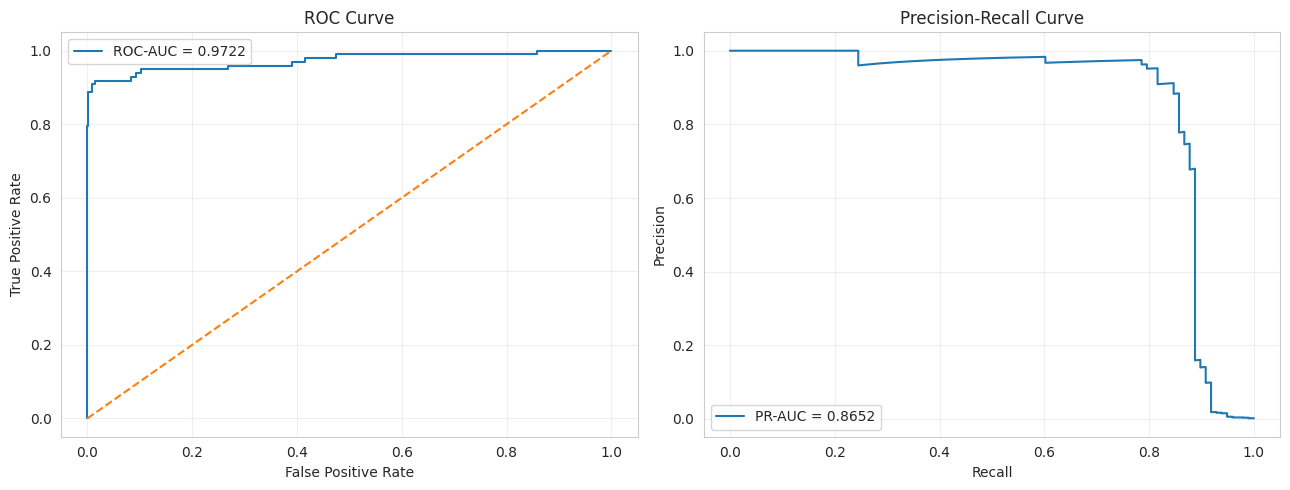

In [27]:
fpr, tpr, _ = roc_curve(y_test, test_prob)
precision_c, recall_c, _ = precision_recall_curve(y_test, test_prob)

roc_auc = roc_auc_score(y_test, test_prob)
pr_auc = average_precision_score(y_test, test_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(recall_c, precision_c, label=f"PR-AUC = {pr_auc:.4f}")
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 27. XGBoost feature importance

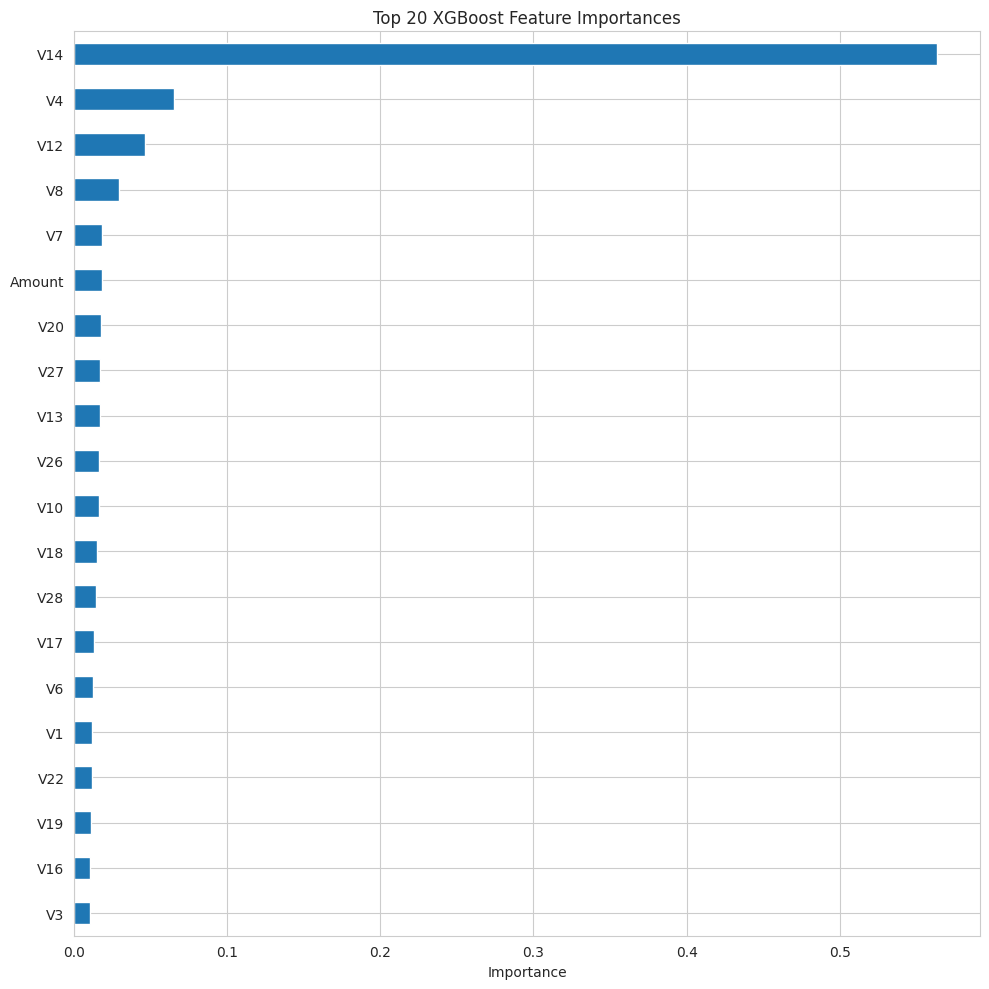

,Importance
V14,0.563504
V4,0.065388
V12,0.046169
V8,0.029167
V7,0.018317
Amount,0.017998
V20,0.017302
V27,0.016893
V13,0.016618
V26,0.016476


In [28]:
# XGBoost feature importance (final_xgb is fitted in the final-refit cell).
importance = pd.Series(
    final_xgb.feature_importances_,
    index=X_train_final.columns,
    name="Importance"
).sort_values(ascending=False)

plt.figure(figsize=(10, 10))
importance.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.head(20).to_frame())


## 28. Optional SHAP explainability

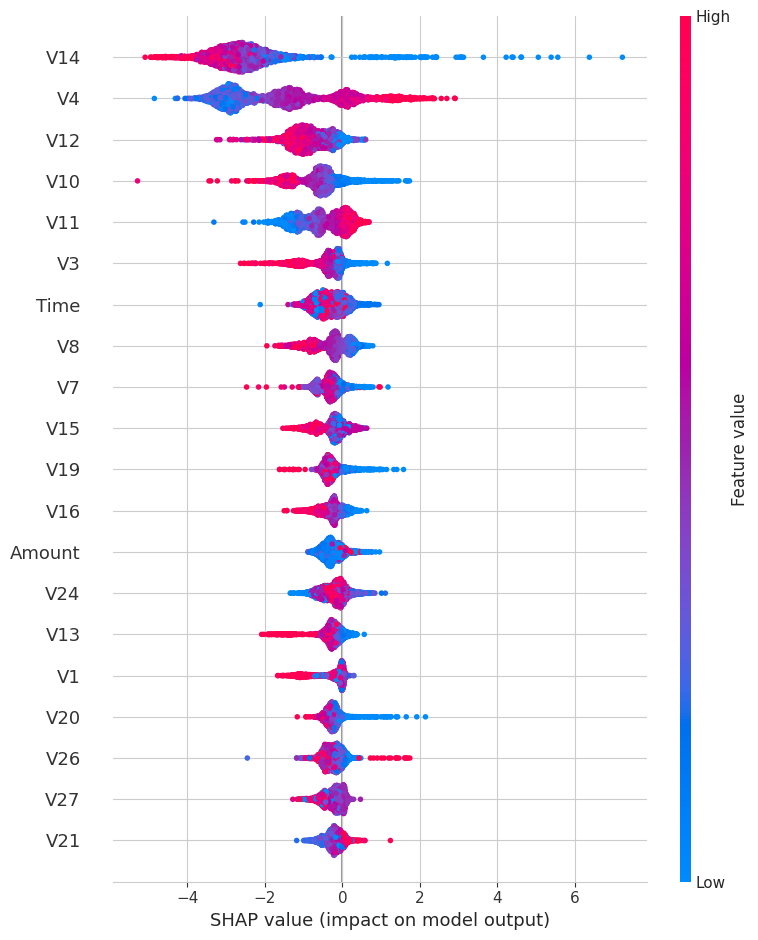

In [29]:
try:
    import shap

    sample_n = min(3000, len(X_test))
    X_shap = X_test.sample(sample_n, random_state=RANDOM_STATE)

    explainer = shap.TreeExplainer(final_xgb)
    shap_values = explainer.shap_values(X_shap)

    shap.summary_plot(shap_values, X_shap, show=True)

except Exception as e:
    print("SHAP section skipped:", repr(e))


## 29. Save the final model and inference settings

In [30]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(
    final_stacking_model,
    "artifacts/final_hybrid_stacking_model.joblib"
)

with open("artifacts/decision_threshold.txt", "w") as f:
    f.write(str(best_threshold))

with open("artifacts/feature_names.txt", "w") as f:
    f.write("\n".join(X.columns.tolist()))

print("Saved:")
print(" - artifacts/final_hybrid_stacking_model.joblib")
print(" - artifacts/decision_threshold.txt")
print(" - artifacts/feature_names.txt")


Saved:
 - artifacts/final_hybrid_stacking_model.joblib
 - artifacts/decision_threshold.txt
 - artifacts/feature_names.txt


## 30. Example inference function

In [31]:
def predict_fraud(new_data):
    new_data = new_data[X.columns].copy()
    probabilities = final_stacking_model.predict_proba(new_data)[:, 1]
    predictions = (probabilities >= best_threshold).astype(int)

    result = new_data.copy()
    result["Fraud_Probability"] = probabilities
    result["Prediction"] = predictions
    return result

# Example:
# sample = X_test.iloc[:5].copy()
# display(predict_fraud(sample))


# 31. Final project conclusions

This notebook covers:
- Leakage-safe splitting
- Class weighting
- Random undersampling
- SMOTE
- SMOTETomek
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- HistGradientBoosting
- XGBoost
- LightGBM
- CatBoost
- KNN
- SVM
- Neural Network
- Hyperparameter tuning
- Hybrid stacking ensemble
- Threshold optimization
- Final test evaluation
- ROC/PR curves
- Feature importance
- Optional SHAP
- Model saving

